<a href="https://colab.research.google.com/github/amsalu2212/DS-Ass3/blob/main/DS_A3_RegressionBlDiagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS-A3 — Regression Baseline and Diagnostics

**Student:** Amsalu Tessema Adgeh  
**Student ID:** 2026A8000929002  
**Course:** Data Science

## Purpose

This is a **stand-alone notebook**: it does not call `run_analysis.py`, read a project CSV, or require any companion project files. It loads scikit-learn's small, bundled diabetes regression benchmark directly from the installed package, then performs the analysis from start to finish. The data are a benchmark for learning regression methods, not a clinical dataset for making medical decisions.

The target is continuous, so this notebook uses regression models (Dummy, Linear Regression, Ridge, and Lasso). Logistic regression is a classification method and is not appropriate for this continuous-target task unless the assignment explicitly asks for a separately defined classification target.

**Reproducibility:** fixed random seed, a single frozen 80/20 split, model selection by cross-validation on training data only, and test data reserved for final evaluation. The notebook records package versions and creates an `ds_a3_outputs/` folder for the tables/figures it exports. No internet access is needed for the dataset.

> Before submitting, check whether your instructor requires the same dataset as A1/A2. Review the findings, adapt the interpretation in your own words, and complete the AI-use disclosure honestly.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import __version__ as sklearn_version
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 20261015
TEST_SIZE = 0.20
OUTPUT_DIR = Path("ds_a3_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

print(f"Python: {sys.version.split()[0]} ({platform.platform()})")
print(f"NumPy: {np.__version__} | pandas: {pd.__version__} | scikit-learn: {sklearn_version}")
print(f"Random seed: {SEED} | Test size: {TEST_SIZE:.0%}")

Python: 3.13.16 (Linux-6.6.122+-x86_64-with-glibc2.39)
NumPy: 2.1.3 | pandas: 2.2.3 | scikit-learn: 1.6.1
Random seed: 20261015 | Test size: 20%


## 2. Load data and inspect it

In [2]:
dataset = load_diabetes(as_frame=True, scaled=True)
X = dataset.data.copy()
y = dataset.target.copy()

# A unique row ID is retained for auditing and error review
data = X.copy()
data["target"] = y
print(f"Rows: {len(data)} | Features: {X.shape[1]} | Missing feature values: {int(X.isna().sum().sum())}")
display(data.head())
display(data.describe().T)

# Save a data preview and data card for transparent provenance.
data.head(10).to_csv(OUTPUT_DIR / "data_preview.csv", index=True)
data_card = {
    "dataset": "scikit-learn load_diabetes (bundled benchmark)",
    "source": "sklearn.datasets.load_diabetes(as_frame=True)",
    "rows": int(len(data)), "features": list(X.columns),
    "target": "quantitative disease-progression measure used by the benchmark",
    "data_access": "bundled with scikit-learn; no network download required",
    "limitations": ["small benchmark dataset", "not for clinical use", "associations are not causal"]
}
(OUTPUT_DIR / "data_card.json").write_text(json.dumps(data_card, indent=2))

Rows: 442 | Features: 10 | Missing feature values: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


535

## 3. Freeze a leakage-free train/test split

In [3]:
# Freeze this split before comparing candidate models. Do not change it based on test scores.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED
)
train_idx = X_train.index
test_idx = X_test.index

In [4]:
assert len(set(train_idx).intersection(set(test_idx))) == 0
assert len(train_idx) + len(test_idx) == len(X)
split_manifest = {
    "dataset": "sklearn load_diabetes",
    "dataset_rows": int(len(X)), "feature_count": int(X.shape[1]),
    "seed": SEED, "test_size": TEST_SIZE,
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "train_indices": [int(i) for i in train_idx],
    "test_indices": [int(i) for i in test_idx],
    "split_rule": "train_test_split(X, y, test_size=0.20, random_state=20261015)",
    "test_set_policy": "held out for final evaluation only; not used for tuning"
}
(OUTPUT_DIR / "split_manifest.json").write_text(json.dumps(split_manifest, indent=2))
leakage_audit = pd.DataFrame([
    {"check":"train/test indices disjoint", "result": not bool(set(train_idx) & set(test_idx)), "evidence":"index intersection is empty"},
    {"check":"all rows accounted for", "result": len(train_idx)+len(test_idx)==len(X), "evidence":f"{len(train_idx)} train + {len(test_idx)} test = {len(X)} total"},
    {"check":"scaling fit only within model pipeline", "result":True, "evidence":"StandardScaler is inside each Pipeline and CV fold"},
    {"check":"hyperparameter tuning uses training data only", "result":True, "evidence":"GridSearchCV.fit called only on X_train/y_train"},
    {"check":"test set used for model selection", "result":False, "evidence":"test metrics computed after CV selection; no retuning based on them"},
])
display(leakage_audit)
print(f"Frozen split: {len(X_train)} training rows and {len(X_test)} test rows.")
leakage_audit.to_csv(OUTPUT_DIR / "leakage_audit.csv", index=False)

,check,result,evidence
0,train/test indices disjoint,True,index intersection is empty
1,all rows accounted for,True,353 train + 89 test = 442 total
2,scaling fit only within model pipeline,True,StandardScaler is inside each Pipeline and CV ...
3,hyperparameter tuning uses training data only,True,GridSearchCV.fit called only on X_train/y_train
4,test set used for model selection,False,test metrics computed after CV selection; no r...


Frozen split: 353 training rows and 89 test rows.


## 4. Fit baseline and candidate models

In [5]:
# Naive baseline: predict the training-target mean for every case.
models = {
    "Dummy mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Ridge (CV-tuned)": Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
    "Lasso (CV-tuned)": Pipeline([("scale", StandardScaler()), ("model", Lasso(max_iter=50000))]),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
searches = {}
searches["Ridge (CV-tuned)"] = GridSearchCV(
    models["Ridge (CV-tuned)"], {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, refit=True
).fit(X_train, y_train)
searches["Lasso (CV-tuned)"] = GridSearchCV(
    models["Lasso (CV-tuned)"], {"model__alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, refit=True
).fit(X_train, y_train)

fitted = {"Dummy mean baseline": models["Dummy mean baseline"].fit(X_train, y_train)}
fitted["Linear regression"] = models["Linear regression"].fit(X_train, y_train)
fitted["Ridge (CV-tuned)"] = searches["Ridge (CV-tuned)"].best_estimator_
fitted["Lasso (CV-tuned)"] = searches["Lasso (CV-tuned)"].best_estimator_

for name, search in searches.items():
    print(f"{name}: best parameters = {search.best_params_}; mean CV RMSE = {-search.best_score_:.3f}")

Ridge (CV-tuned): best parameters = {'model__alpha': 1.0}; mean CV RMSE = 54.932
Lasso (CV-tuned): best parameters = {'model__alpha': 0.5}; mean CV RMSE = 54.882


## 5. Compare models on the held-out test set

In [6]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

rows, predictions = [], {}
for name, model in fitted.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {"model": name, **regression_metrics(y_test, pred)}
    if name in searches:
        row["best_alpha"] = float(searches[name].best_params_["model__alpha"])
        row["best_cv_RMSE"] = float(-searches[name].best_score_)
    else:
        row["best_alpha"] = np.nan
        row["best_cv_RMSE"] = np.nan
    rows.append(row)
comparison = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(comparison.round(3))
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

# Keep a case-level record of test predictions from every candidate.
prediction_table = pd.DataFrame({"row_index": X_test.index, "actual": y_test.to_numpy()})
for name, pred in predictions.items():
    safe = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_")
    prediction_table[f"pred_{safe}"] = pred
prediction_table["linear_residual"] = y_test.to_numpy() - predictions["Linear regression"]
prediction_table["linear_abs_error"] = prediction_table["linear_residual"].abs()
prediction_table.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Reminder: use the test scores for reporting, not to retune the models.")

,model,RMSE,MAE,R2,best_alpha,best_cv_RMSE
0,Lasso (CV-tuned),53.992,42.989,0.518,0.5,54.882
1,Ridge (CV-tuned),54.207,42.891,0.514,1.0,54.932
2,Linear regression,54.281,42.918,0.513,NaN,NaN
3,Dummy mean baseline,77.976,65.799,-0.005,NaN,NaN


Reminder: use the test scores for reporting, not to retune the models.


## 6. Residual diagnostics

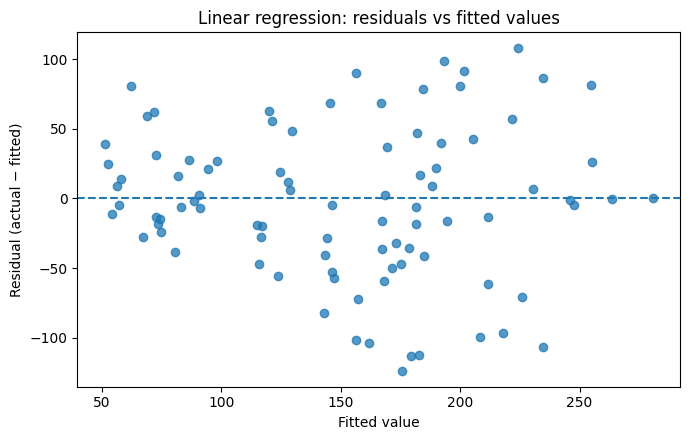

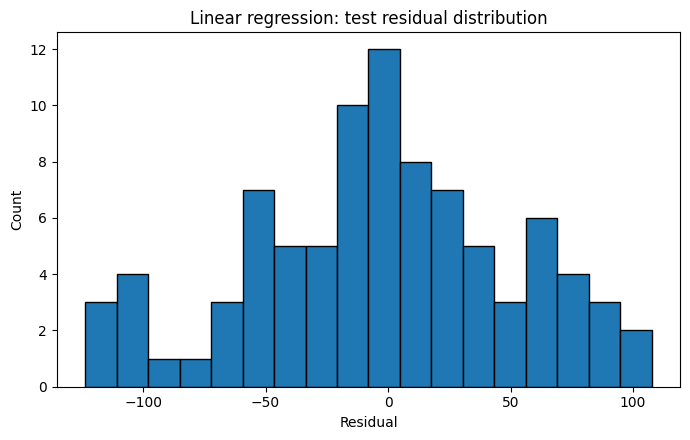

{
  "test_residual_mean": -3.047989483065765,
  "test_residual_std": 54.5020560854325,
  "test_residual_min": -123.61802163329216,
  "test_residual_max": 107.58551526777578,
  "interpretation_note": "Visual diagnostics reveal possible patterns; they do not prove assumptions or causality."
}


291

In [7]:
linear_pred = predictions["Linear regression"]
residuals = y_test.to_numpy() - linear_pred

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(linear_pred, residuals, alpha=0.75)
ax.axhline(0, linestyle="--")
ax.set(title="Linear regression: residuals vs fitted values", xlabel="Fitted value", ylabel="Residual (actual − fitted)")
plt.tight_layout(); plt.show()
fig.savefig(OUTPUT_DIR / "residuals_vs_fitted.png", dpi=160, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(residuals, bins=18, edgecolor="black")
ax.set(title="Linear regression: test residual distribution", xlabel="Residual", ylabel="Count")
plt.tight_layout(); plt.show()
fig.savefig(OUTPUT_DIR / "residual_distribution.png", dpi=160, bbox_inches="tight")

residual_summary = {
    "test_residual_mean": float(np.mean(residuals)),
    "test_residual_std": float(np.std(residuals, ddof=1)),
    "test_residual_min": float(np.min(residuals)),
    "test_residual_max": float(np.max(residuals)),
    "interpretation_note": "Visual diagnostics reveal possible patterns; they do not prove assumptions or causality."
}
print(json.dumps(residual_summary, indent=2))
(OUTPUT_DIR / "residual_summary.json").write_text(json.dumps(residual_summary, indent=2))

## 7. Influence and heteroscedasticity diagnostics

In [8]:
# statsmodels is used for classical OLS diagnostics. It is included in the requirements below.
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# OLS on standardized training features; standardization is fit only on training data.
ols_scaler = StandardScaler().fit(X_train)
X_train_scaled = ols_scaler.transform(X_train)
ols = sm.OLS(np.asarray(y_train), sm.add_constant(X_train_scaled)).fit()
influence = ols.get_influence()
influence_table = pd.DataFrame({
    "row_index": X_train.index.to_numpy(),
    "studentized_residual": influence.resid_studentized_external,
    "leverage": influence.hat_matrix_diag,
    "cooks_distance": influence.cooks_distance[0]
}).sort_values("cooks_distance", ascending=False)
display(influence_table.head(10).round(4))
influence_table.to_csv(OUTPUT_DIR / "influence_diagnostics_train.csv", index=False)

bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(ols.resid, ols.model.exog)
hetero = {"breusch_pagan_lm_stat": float(bp_lm), "lm_p_value": float(bp_lm_p),
          "f_statistic": float(bp_f), "f_p_value": float(bp_f_p),
          "caution": "A small p-value is evidence against constant variance under this test; it is not a measure of predictive performance."}
print(json.dumps(hetero, indent=2))
(OUTPUT_DIR / "heteroscedasticity_test.json").write_text(json.dumps(hetero, indent=2))

,row_index,studentized_residual,leverage,cooks_distance
220,382,-2.3090,0.0694,0.0357
167,123,-1.7084,0.0883,0.0255
186,58,1.4831,0.1082,0.0242
38,304,2.4889,0.0414,0.0240
17,387,2.0632,0.0567,0.0231
59,169,-1.2329,0.1420,0.0228
125,32,1.6566,0.0814,0.0220
22,92,-2.6720,0.0330,0.0217
348,102,2.7719,0.0293,0.0207
279,141,1.6405,0.0749,0.0197


{
  "breusch_pagan_lm_stat": 12.28448012115959,
  "lm_p_value": 0.2664684044723697,
  "f_statistic": 1.2330791984264688,
  "f_p_value": 0.2683813244270149,
  "caution": "A small p-value is evidence against constant variance under this test; it is not a measure of predictive performance."
}


290

## 8. Learning curve

,training_rows,train_RMSE_mean,train_RMSE_std,cv_RMSE_mean,cv_RMSE_std
0,56,51.063,2.967,61.079,4.562
1,112,52.960,2.309,57.423,4.405
2,169,52.960,0.885,56.121,4.871
3,225,53.076,0.649,55.563,3.729
4,282,53.307,0.902,54.999,3.533


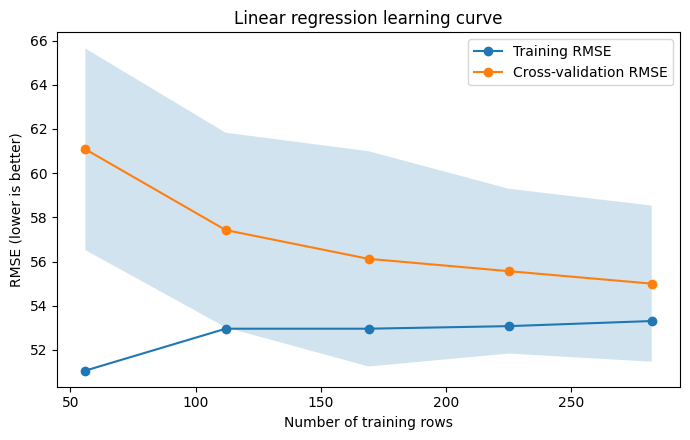

In [9]:
learning_model = Pipeline([("scale", StandardScaler()), ("model", LinearRegression())])
train_sizes, train_scores, valid_scores = learning_curve(
    learning_model, X_train, y_train, cv=cv,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
)
learning_df = pd.DataFrame({
    "training_rows": train_sizes,
    "train_RMSE_mean": -train_scores.mean(axis=1),
    "train_RMSE_std": train_scores.std(axis=1),
    "cv_RMSE_mean": -valid_scores.mean(axis=1),
    "cv_RMSE_std": valid_scores.std(axis=1),
})
display(learning_df.round(3))
learning_df.to_csv(OUTPUT_DIR / "learning_curve.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(train_sizes, learning_df["train_RMSE_mean"], marker="o", label="Training RMSE")
ax.plot(train_sizes, learning_df["cv_RMSE_mean"], marker="o", label="Cross-validation RMSE")
ax.fill_between(train_sizes, learning_df["cv_RMSE_mean"]-learning_df["cv_RMSE_std"], learning_df["cv_RMSE_mean"]+learning_df["cv_RMSE_std"], alpha=0.2)
ax.set(title="Linear regression learning curve", xlabel="Number of training rows", ylabel="RMSE (lower is better)")
ax.legend(); plt.tight_layout(); plt.show()
fig.savefig(OUTPUT_DIR / "learning_curve.png", dpi=160, bbox_inches="tight")

## 9. Critical slices and largest test errors

In [10]:
# Slice cut points are computed on training BMI values only, then applied to the test set.
if "bmi" in X.columns:
    bmi_q = X_train["bmi"].quantile([0.25, 0.50, 0.75]).to_numpy()
    bmi_test = X_test["bmi"].to_numpy()
    bmi_groups = np.digitize(bmi_test, bmi_q, right=True)
    slice_names = {0: "BMI: lowest training quartile", 1: "BMI: second quartile", 2: "BMI: third quartile", 3: "BMI: highest training quartile"}
    slice_rows = []
    for group_id, label in slice_names.items():
        mask = bmi_groups == group_id
        if mask.sum():
            slice_rows.append({"slice": label, "n": int(mask.sum()), **regression_metrics(y_test.to_numpy()[mask], linear_pred[mask])})
    slice_metrics = pd.DataFrame(slice_rows)
    display(slice_metrics.round(3))
    slice_metrics.to_csv(OUTPUT_DIR / "critical_slice_metrics.csv", index=False)
    (OUTPUT_DIR / "slice_cutpoints.json").write_text(json.dumps({"feature":"bmi", "training_quantiles_25_50_75":[float(v) for v in bmi_q]}, indent=2))
else:
    print("BMI feature not available; define a meaningful slice using training data only.")

error_cases = pd.DataFrame({
    "row_index": X_test.index.to_numpy(), "actual": y_test.to_numpy(),
    "predicted_linear": linear_pred, "residual": residuals, "absolute_error": np.abs(residuals)
}).sort_values("absolute_error", ascending=False)
display(error_cases.head(10).round(3))
error_cases.to_csv(OUTPUT_DIR / "largest_test_errors.csv", index=False)

,slice,n,RMSE,MAE,R2
0,BMI: lowest training quartile,24,37.981,31.444,0.072
1,BMI: second quartile,17,50.946,37.644,0.176
2,BMI: third quartile,21,55.723,47.206,0.424
3,BMI: highest training quartile,27,66.187,53.103,0.396


,row_index,actual,predicted_linear,residual,absolute_error
55,380,52.0,175.618,-123.618,123.618
21,274,66.0,179.302,-113.302,113.302
75,211,70.0,182.672,-112.672,112.672
83,290,332.0,224.414,107.586,107.586
80,147,128.0,234.741,-106.741,106.741
69,363,58.0,161.868,-103.868,103.868
72,417,55.0,156.478,-101.478,101.478
28,310,109.0,208.517,-99.517,99.517
8,152,292.0,193.396,98.604,98.604
59,376,121.0,217.810,-96.810,96.810


## 10. Coefficients and permutation importance

model,Lasso (CV-tuned),Linear regression,Ridge (CV-tuned)
feature,,,
age,0.494,0.738,0.812
bmi,25.452,25.162,25.227
bp,12.583,13.178,13.094
s1,-4.970,-40.062,-29.837
s2,0.000,28.674,20.437
s3,-11.340,1.398,-2.777
s4,0.000,1.369,0.554
s5,24.442,37.825,33.919
s6,3.665,3.884,3.953


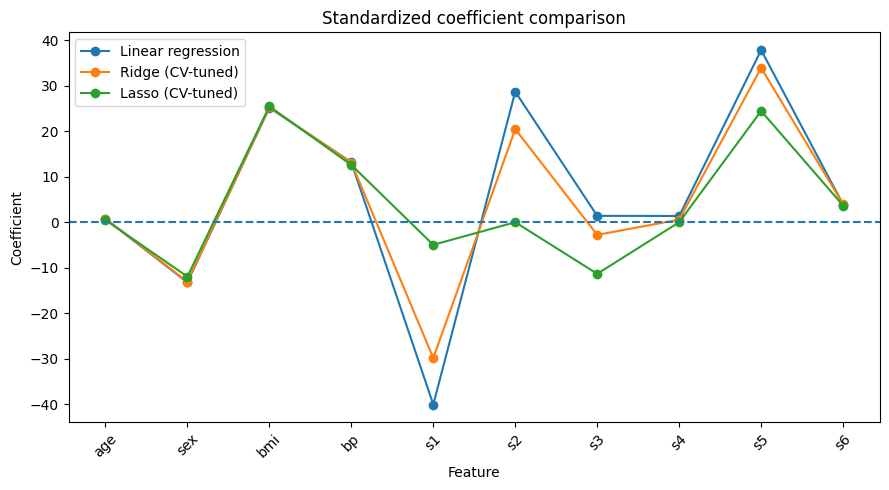

,feature,importance_mean,importance_std
4,s1,25.6211,4.4898
8,s5,20.5305,2.9087
2,bmi,11.4756,1.9765
5,s2,11.0444,2.6582
3,bp,4.6424,1.2743
1,sex,0.8226,0.8452
9,s6,0.0871,0.5114
7,s4,0.0827,0.1149
6,s3,0.0159,0.1367
0,age,-0.0533,0.0789


In [11]:
# Standardized coefficients help compare scale across features; they remain associations, not causal effects.
coef_rows = []
for name in ["Linear regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"]:
    estimator = fitted[name].named_steps["model"]
    for feature, coef in zip(X.columns, estimator.coef_):
        coef_rows.append({"model": name, "feature": feature, "standardized_coefficient": float(coef)})
coef_df = pd.DataFrame(coef_rows)
display(coef_df.pivot(index="feature", columns="model", values="standardized_coefficient").round(3))
coef_df.to_csv(OUTPUT_DIR / "standardized_coefficients.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for name in ["Linear regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"]:
    subset = coef_df[coef_df.model == name].set_index("feature").reindex(X.columns)
    ax.plot(subset.index, subset["standardized_coefficient"], marker="o", label=name)
ax.axhline(0, linestyle="--")
ax.set(title="Standardized coefficient comparison", ylabel="Coefficient", xlabel="Feature")
ax.tick_params(axis="x", rotation=45); ax.legend(); plt.tight_layout(); plt.show()
fig.savefig(OUTPUT_DIR / "coefficient_comparison.png", dpi=160, bbox_inches="tight")

perm = permutation_importance(fitted["Linear regression"], X_test, y_test,
                              scoring="neg_root_mean_squared_error", n_repeats=20,
                              random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({"feature": X.columns, "importance_mean": perm.importances_mean,
                        "importance_std": perm.importances_std}).sort_values("importance_mean", ascending=False)
display(perm_df.round(4))
perm_df.to_csv(OUTPUT_DIR / "permutation_importance_test.csv", index=False)

## 11. Interpret results carefully

In [12]:
best_row = comparison.iloc[0]
base_row = comparison[comparison.model == "Dummy mean baseline"].iloc[0]
relative_rmse_change = (base_row.RMSE - best_row.RMSE) / base_row.RMSE * 100
print(f"Lowest test RMSE among candidates: {best_row['model']} (RMSE={best_row.RMSE:.3f}, MAE={best_row.MAE:.3f}, R²={best_row.R2:.3f}).")
print(f"Relative RMSE reduction versus the mean baseline: {relative_rmse_change:.1f}% (descriptive for this one split).")
print("Do not interpret this single held-out split as a guarantee of generalization to other populations.")
print("Coefficients and permutation importance are predictive associations, not causal effects.")
print("Inspect the residual plot, influence flags, heteroscedasticity test, learning curve, slices, and largest errors before making a claim.")

Lowest test RMSE among candidates: Lasso (CV-tuned) (RMSE=53.992, MAE=42.989, R²=0.518).
Relative RMSE reduction versus the mean baseline: 30.8% (descriptive for this one split).
Do not interpret this single held-out split as a guarantee of generalization to other populations.
Coefficients and permutation importance are predictive associations, not causal effects.
Inspect the residual plot, influence flags, heteroscedasticity test, learning curve, slices, and largest errors before making a claim.


## 12. Claim boundary, limitations, and reproducibility checklist

### Defensible claim boundary

- The comparison describes performance on one fixed test split of a small, bundled benchmark.
- Cross-validation is used only on training data to select Ridge/Lasso regularization strengths.
- Residual, influence, heteroscedasticity, and slice analyses are diagnostic evidence; none alone proves a model is valid or invalid.
- Coefficients and permutation importance indicate predictive associations. They do **not** establish causal effects.
- The dataset and model are for educational regression analysis, not clinical decision-making or individual diagnosis.

### AI-use disclosure reminder

Record the AI tool and tasks for which it was used, which suggestions were accepted or rejected, and how outputs were independently verified. Do not claim that code/results were independently produced if they were not. Confirm that the selected dataset matches your instructor's expectations before submitting.